In [ ]:
import pandas as pd
import numpy as np


# ***Uploading Data***

In [ ]:
from google.colab import files
upload=files.upload()

Saving goibibo_flights_01.csv to goibibo_flights_01.csv


In [ ]:
df=pd.read_csv("goibibo_flights_01.csv")

In [ ]:
raw=df.copy()

# ***Inspecting Data***

In [ ]:
pd.set_option("display.max_columns", None)

In [ ]:
df.sample(20,random_state=42)

,flight date,airline,flight_num,class,from,dep_time,to,arr_time,duration,price,stops
283985,10 Jul 2023,Air India,AI-541,business,Hyderabad,16:15,Kolkata,09:00,16h 45m,"52,483",1-stop
261771,29-06-2023,Vistara,UK-772,business,Kolkata,10:25,Delhi,08:35,1330 min,"62,507",1-stop
17220,31-07-2023,Indigo,6E-6205,economy,Delhi,12:55,Bangalore,22:50,09h 55m,"4,210",1-stop
80505,2023/07/19,Indigo,6E-6463,economy,Mumbai,06:55,Chennai,12:00,NaN,"4,110",1-stop
60258,06-08-2023,Vistara,UK-902,economy,Mumbai,15:45,Bangalore,22:40,06h 55m,"6,515",1-stop
85363,03-07-2023,Air India,AI-610,economy,Bangalore,19:10,Delhi,18:15,1385 min,"10,851",1-stop
195345,13-07-2023,Vistara,UK-836,economy,Chennai,10:45,Bangalore,20:55,10h 10m,"6,496",2+-stop
288110,29-06-2023,AIR INDIA,AI-672,business,Chennai,14:55,Delhi,12:15,21h 20m,"45,863",1-stop
71053,02-07-2023,GO FIRST,G8-391,economy,Mumbai,13:30,Hyderabad,22:40,09h 10m,"4,305",1-stop
276472,2023/07/23,Air India,AI-543,business,Hyderabad,11:20,Delhi,13:50,02h 30m,"24,484",non-stop


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300561 entries, 0 to 300560
Data columns (total 11 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   flight date  294585 non-null  object
 1   airline      291645 non-null  object
 2   flight_num   291723 non-null  object
 3   class        294578 non-null  object
 4   from         294532 non-null  object
 5   dep_time     288651 non-null  object
 6   to           294478 non-null  object
 7   arr_time     288538 non-null  object
 8   duration     287025 non-null  object
 9   price        285460 non-null  object
 10  stops        288516 non-null  object
dtypes: object(11)
memory usage: 25.2+ MB


In [ ]:
for col in df.columns:
  print(col,"-->",df[col].isna().mean().round(4)*100)

flight date --> 1.9900000000000002
airline --> 2.97
flight_num --> 2.94
class --> 1.9900000000000002
from --> 2.01
dep_time --> 3.9600000000000004
to --> 2.02
arr_time --> 4.0
duration --> 4.5
price --> 5.0200000000000005
stops --> 4.01


In [ ]:
print(df.duplicated().sum())

257


# ***DATA CLEANING***

In [ ]:
df.columns=df.columns.str.strip().str.replace(" ","_").str.lower()

In [ ]:
col = ["airline", "class", "from", "to"]

for c in col:
  df[c]=df[c].str.strip().str.lower()

In [ ]:
col = ["airline", "class", "from", "to"]

for c in col:
    print(c, "-----", "\n")
    print(df[c].value_counts())
    print("-----" * 10)



airline ----- 

airline
vistara      124174
air india     78580
indigo        41878
go first      22509
airasia       15634
spicejet       8768
starair          61
trujet           41
Name: count, dtype: int64
--------------------------------------------------
class ----- 

class
economy     202853
business     91725
Name: count, dtype: int64
--------------------------------------------------
from ----- 

from
delhi        60176
mumbai       59767
bangalore    51188
kolkata      45433
hyderabad    40082
chennai      37886
Name: count, dtype: int64
--------------------------------------------------
to ----- 

to
mumbai       57969
delhi        56281
bangalore    50139
kolkata      48547
hyderabad    41951
chennai      39591
Name: count, dtype: int64
--------------------------------------------------


In [ ]:
df["price"] = df["price"].str.replace("[₹,]", "", regex=True)
df["price"] = pd.to_numeric(df["price"], errors="coerce")

In [ ]:
d1 = pd.to_datetime(df["flight_date"], format="%d-%m-%Y", errors="coerce")
d2 = pd.to_datetime(df["flight_date"], format="%Y/%m/%d", errors="coerce")
d3 = pd.to_datetime(df["flight_date"], format="%d %b %Y", errors="coerce")
df["flight_date"] = d1.fillna(d2).fillna(d3)


In [ ]:
df["stops"]=df["stops"].str.split().str[0].str.lower()

In [ ]:
df["stops"]=df["stops"].replace({
                                 "non-stop":"0",
                                 "1-stop":"1",
                                 "2+-stop":"2"
                                 })

In [ ]:
dep_pm = df[df["dep_time"].str.contains("PM", na=False)]
print(dep_pm["dep_time"])

71        08:15 PM
77        07:50 PM
124       05:45 PM
125       08:40 PM
235       12:50 PM
            ...   
300362    08:30 PM
300398    02:55 PM
300409    12:30 PM
300480    02:55 PM
300488    12:30 PM
Name: dep_time, Length: 6296, dtype: object


In [ ]:
dep_pm = raw[raw["dep_time"].str.contains("AM", na=False)]
print(dep_pm["dep_time"])

8         08:00 AM
73        06:30 AM
132       07:15 AM
159       06:25 AM
282       06:25 AM
            ...   
300095    06:10 AM
300175    10:45 AM
300206    07:00 AM
300348    10:45 AM
300520    11:20 AM
Name: dep_time, Length: 5145, dtype: object


In [ ]:
for col in ["dep_time", "arr_time"]:
    t24 = pd.to_datetime(df[col], format="%H:%M", errors="coerce")
    t12 = pd.to_datetime(df[col], format="%I:%M %p", errors="coerce")
    df[col] = t24.fillna(t12).dt.strftime("%H:%M")

In [ ]:
hours = df["duration"].str.extract(r"(\d+)\s*h")[0].astype(float)
mins  = df["duration"].str.extract(r"(\d+)\s*m")[0].astype(float)

df["duration_min"]=hours.fillna(0)*60 + mins.fillna(0)
df.loc[hours.isna() & mins.isna(), "duration_min"]=np.nan
df=df.drop(columns=["duration"])



In [ ]:
# 8. Recover missing airline from flight number
df["code"] = df["flight_num"].str.split("-").str[0]
code_map = df.dropna(subset=["airline"]).groupby("code")["airline"].agg(lambda x: x.mode()[0])
df["airline"] = df["airline"].fillna(df["code"].map(code_map))
df = df.drop(columns="code")

In [ ]:
# 9. Missing values
df = df.dropna(subset=["price", "flight_date", "class", "from", "to"])
df["duration_min"] = df["duration_min"].fillna(
    df.groupby(["from", "to", "stops"])["duration_min"].transform("median"))
df = df.dropna(subset=["duration_min"])
df["stops"] = df["stops"].fillna("unknown")
df["airline"] = df["airline"].fillna("Unknown")

In [ ]:
df = df.drop_duplicates()

In [ ]:
print("Rows before:", raw.shape[0], "| Rows after:", len(df))
print(df.isnull().sum())
print(df.dtypes)

Rows before: 300561 | Rows after: 262642
flight_date         0
airline             0
flight_num       7732
class               0
from                0
dep_time        10439
to                  0
arr_time        10518
price               0
stops               0
duration_min        0
dtype: int64
flight_date     datetime64[ns]
airline                 object
flight_num              object
class                   object
from                    object
dep_time                object
to                      object
arr_time                object
price                  float64
stops                   object
duration_min           float64
dtype: object


In [ ]:
print(raw["class"].str.strip().str.lower().value_counts(normalize=True))
print(df["class"].value_counts(normalize=True))

class
economy     0.688622
business    0.311378
Name: proportion, dtype: float64
class
economy     0.689075
business    0.310925
Name: proportion, dtype: float64


In [ ]:
df.to_csv("flights_clean.csv", index=False)

In [ ]:
# files.download("flights_clean.csv")

# ***EDA***

In [ ]:
df["flight_date"] = pd.to_datetime(df["flight_date"], errors="coerce")

def iqr_flag(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return (s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)

df["price_outlier"] = df.groupby("class")["price"].transform(iqr_flag)
df["dur_outlier"]   = df.groupby("class")["duration_min"].transform(iqr_flag)

summary = df.groupby("class").agg(
    rows=("price", "size"),
    price_min=("price", "min"), price_median=("price", "median"), price_max=("price", "max"),
    price_outliers=("price_outlier", "sum"),
    dur_median=("duration_min", "median"), dur_max=("duration_min", "max"),
    dur_outliers=("dur_outlier", "sum"),
)
summary["price_out_%"] = (summary.price_outliers / summary.rows * 100).round(1)
summary["dur_out_%"]   = (summary.dur_outliers / summary.rows * 100).round(1)
print(summary.T)


class           business   economy
rows             81662.0  180980.0
price_min        12180.0    1116.0
price_median     53961.0    5830.0
price_max       124917.0   42772.0
price_outliers    3183.0   12179.0
dur_median         780.0     625.0
dur_max           2865.0    2990.0
dur_outliers       238.0    2799.0
price_out_%          3.9       6.7
dur_out_%            0.3       1.5


In [ ]:
# look at the extreme rows before deciding
print(df[df.price_outlier].sort_values("price", ascending=False)
        .head(10)[["airline", "class", "from", "to", "stops", "duration_min", "price"]])
print(df[df.dur_outlier].sort_values("duration_min", ascending=False)
        .head(10)[["airline", "class", "from", "to", "stops", "duration_min", "price"]])

        airline     class       from         to stops  duration_min     price
261740  vistara  business    kolkata      delhi     1         810.0  124917.0
216407  vistara  business      delhi    kolkata     2         655.0  119067.0
216170  vistara  business      delhi    kolkata     2        1265.0  118310.0
277724  vistara  business  hyderabad     mumbai     1         985.0  116939.0
271373  vistara  business    kolkata  hyderabad     1         570.0  116426.0
290967  vistara  business    chennai     mumbai     1         905.0  116425.0
230421  vistara  business     mumbai  bangalore     1        1350.0  116241.0
219497  vistara  business      delhi  hyderabad     2        1645.0  116225.0
216169  vistara  business      delhi    kolkata     2        1265.0  116151.0
241886  vistara  business     mumbai    chennai     1        1310.0  113643.0
          airline     class       from         to stops  duration_min    price
194658  air india   economy    chennai  bangalore     1        

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
sns.set_theme(style="whitegrid")
df = df.copy()

# --- helper columns ---
df["dow"] = df["flight_date"].dt.day_name()
hr = pd.to_datetime(df["dep_time"], format="%H:%M", errors="coerce").dt.hour
df["time_of_day"] = pd.cut(hr, bins=[-1,5,11,17,21,24],
        labels=["Night","Morning","Afternoon","Evening","Night2"]).astype(str)
df["time_of_day"] = df["time_of_day"].replace({"Night2":"Night","nan":"Unknown"})

order_dow = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
order_tod = ["Morning","Afternoon","Evening","Night","Unknown"]

def show(title):
    plt.title(title); plt.tight_layout(); plt.show()


***1***

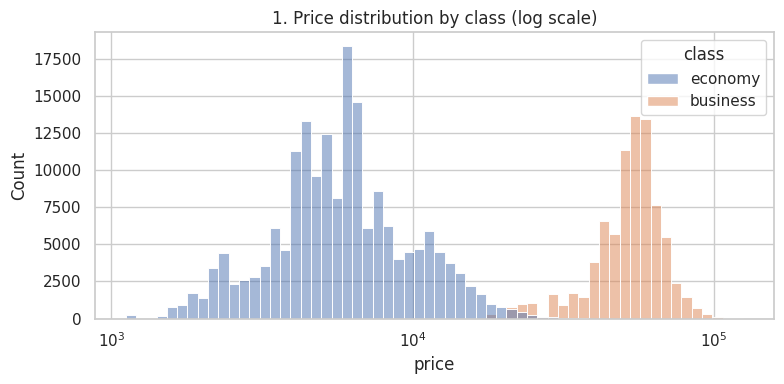

In [ ]:
# 1. Price distribution by class (log scale)
plt.figure(figsize=(8,4))
sns.histplot(data=df, x="price", hue="class", log_scale=True, bins=60)
show("1. Price distribution by class (log scale)")

***2***

***3***

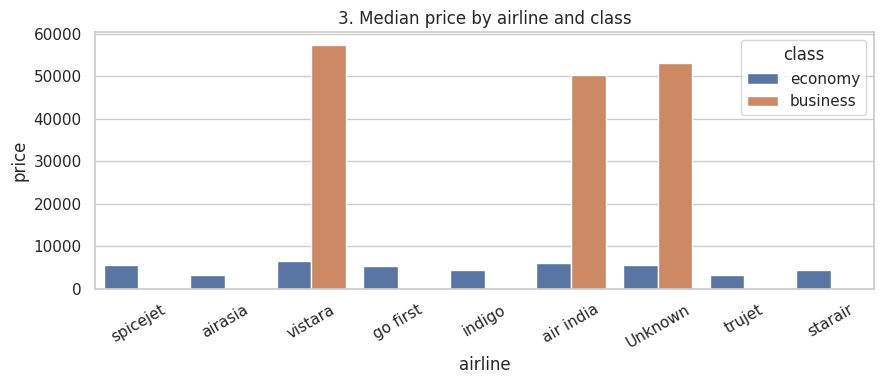

In [ ]:
# 3. Median price by airline and class
plt.figure(figsize=(9,4))
sns.barplot(data=df, x="airline", y="price", hue="class", estimator=np.median, errorbar=None)
plt.xticks(rotation=30); show("3. Median price by airline and class")

***4***

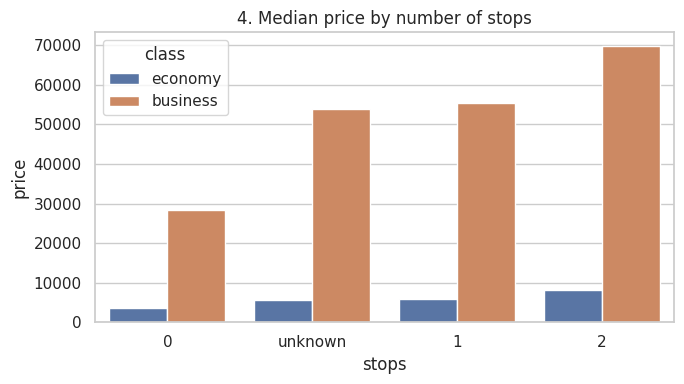

In [ ]:
# 4. Median price by stops
plt.figure(figsize=(7,4))
sns.barplot(data=df, x="stops", y="price", hue="class", estimator=np.median, errorbar=None)
show("4. Median price by number of stops")

***5***

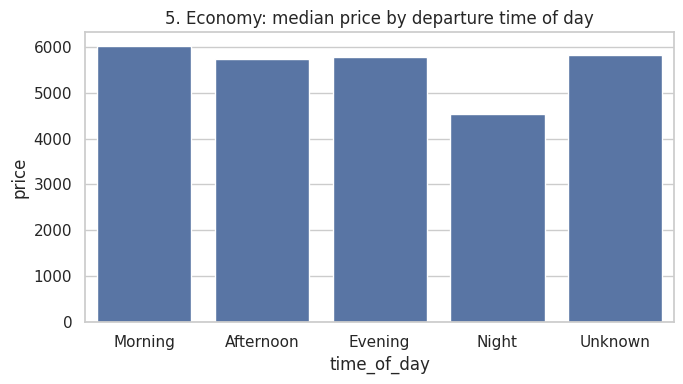

In [ ]:
# 5. Economy: price by time of day
plt.figure(figsize=(7,4))
sns.barplot(data=df[df["class"]=="economy"], x="time_of_day", y="price",
            order=order_tod, estimator=np.median, errorbar=None)
show("5. Economy: median price by departure time of day")

***6***

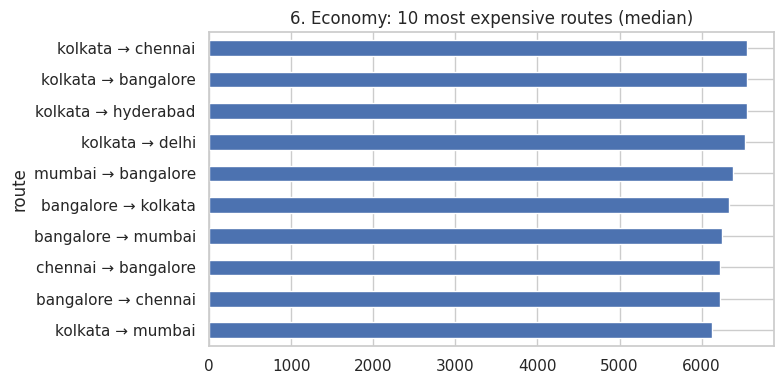

In [ ]:
# 6. Economy: top 10 routes by median price
route = df[df["class"]=="economy"].assign(route=lambda d: d["from"]+" → "+d["to"])
cnt = route["route"].value_counts()
route = route[route["route"].isin(cnt[cnt>=500].index)]
top = route.groupby("route")["price"].median().sort_values(ascending=False).head(10)
plt.figure(figsize=(8,4)); top[::-1].plot(kind="barh")
show("6. Economy: 10 most expensive routes (median)")

***7***

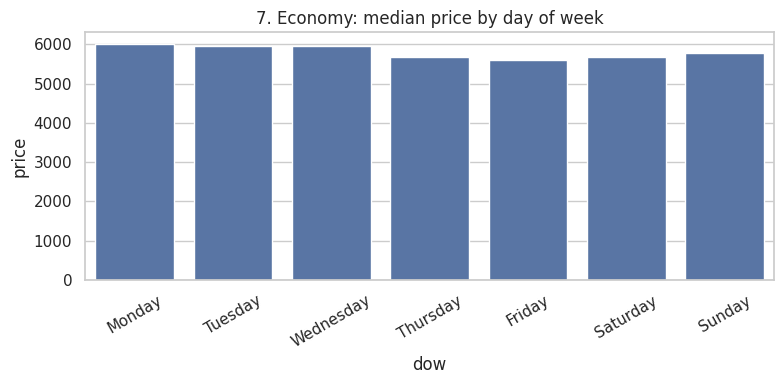

In [ ]:
# 7. Economy: price by day of week
plt.figure(figsize=(8,4))
sns.barplot(data=df[df["class"]=="economy"], x="dow", y="price",
            order=order_dow, estimator=np.median, errorbar=None)
plt.xticks(rotation=30); show("7. Economy: median price by day of week")

***8***

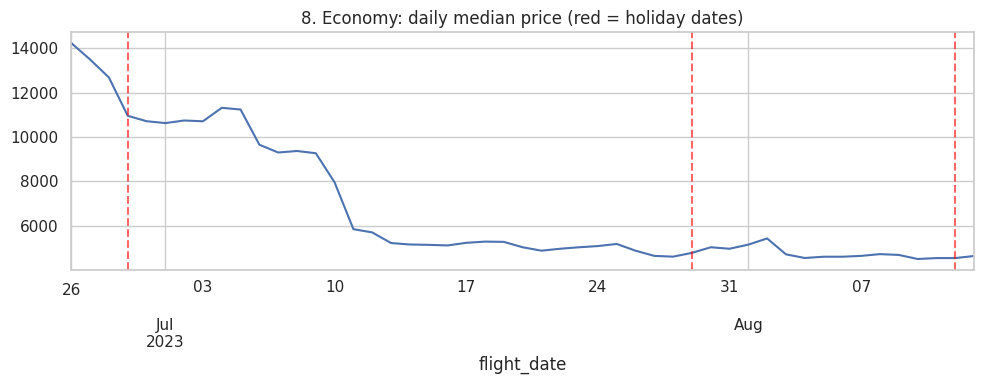

In [ ]:
# 8. Economy: daily median price over time
daily = df[df["class"]=="economy"].groupby("flight_date")["price"].median()
plt.figure(figsize=(10,4)); daily.plot()
for d in ["2023-06-29","2023-07-29","2023-08-12"]:
    plt.axvline(pd.Timestamp(d), color="red", ls="--", alpha=.6)
show("8. Economy: daily median price (red = holiday dates)")

***9***

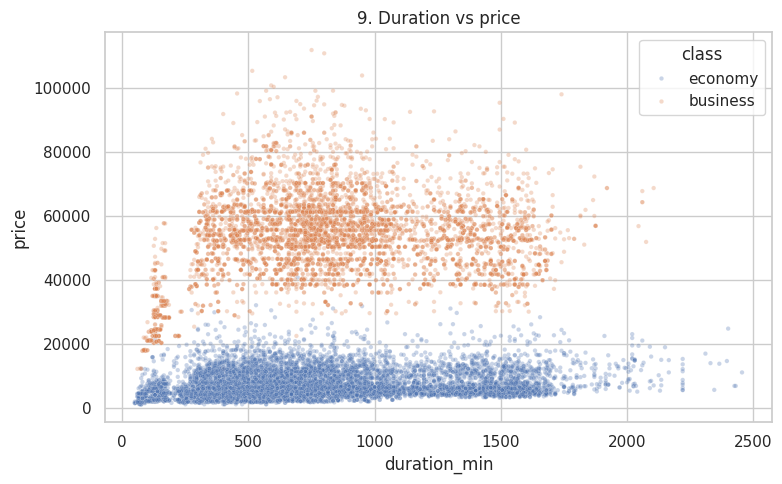

In [ ]:
# 9. Duration vs price
plt.figure(figsize=(8,5))
sns.scatterplot(data=df.sample(min(20000,len(df)), random_state=1),
                x="duration_min", y="price", hue="class", alpha=.3, s=10)
show("9. Duration vs price")

airline
vistara      111820
air india     70572
indigo        37611
go first      20253
airasia       14157
spicejet       7905
Unknown         235
starair          55
trujet           34
Name: count, dtype: int64 

stops
1          211028
0           30314
2           11182
unknown     10118
Name: count, dtype: int64 

time_of_day
Morning      106099
Afternoon     66696
Evening       62662
Night         16746
Unknown       10439
Name: count, dtype: int64 

business under 22k: 1243
          airline    from         to stops  duration_min    price
230491    vistara  mumbai  bangalore     0         105.0  20994.0
230492    vistara  mumbai  bangalore     0         110.0  20994.0
230493  air india  mumbai  bangalore     0         100.0  20994.0
230494  air india  mumbai  bangalore     0         105.0  20994.0
230564    vistara  mumbai  bangalore     0         100.0  20994.0
230565    vistara  mumbai  bangalore     0         105.0  20994.0
230566    vistara  mumbai  bangalore     0         

<Axes: title={'center': 'Price vs group median, by date (1.0 = normal)'}, xlabel='flight_date'>

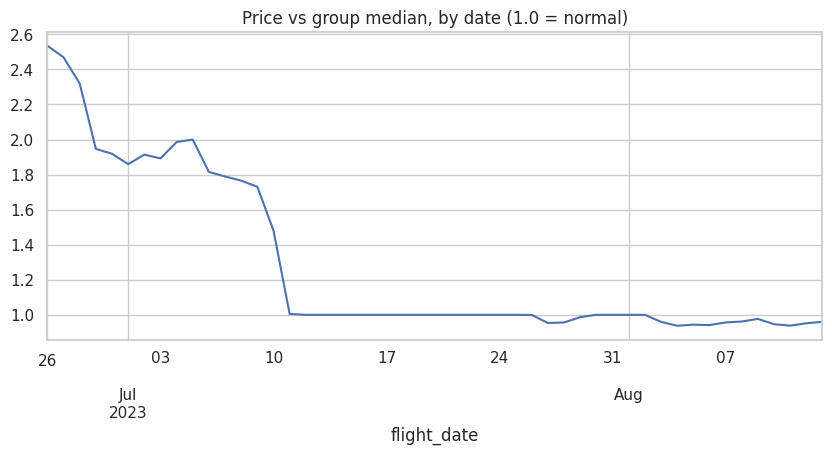

In [ ]:
# 1. Counts: how big are the Unknown groups?
for col in ["airline", "stops", "time_of_day"]:
    print(df[col].astype(str).value_counts(), "\n")

# 2. Business rows with a very low price (real or wrong label?)
low = df[(df["class"] == "business") & (df["price"] < 22000)]
print("business under 22k:", len(low))
print(low[["airline", "from", "to", "stops", "duration_min", "price"]].head(10), "\n")

# 3. Non-stop flights with a very long duration (likely errors)
bad = df[(df["stops"].astype(str) == "0") & (df["duration_min"] > 480)]
print("non-stop over 8 hours:", len(bad))
print(bad[["airline", "from", "to", "duration_min", "price"]].head(10), "\n")

# 4. Does the date effect hold inside the same airline + route + stops?
eco = df[df["class"] == "economy"].copy()
grp = ["airline", "from", "to", "stops"]
eco["rel_price"] = eco["price"] / eco.groupby(grp)["price"].transform("median")
daily_rel = eco.groupby("flight_date")["rel_price"].median()
print(daily_rel.head(5)); print(daily_rel.tail(5))
daily_rel.plot(figsize=(10, 4), title="Price vs group median, by date (1.0 = normal)")

# ***FEATURE ENGINEERING***

In [ ]:
m = df.copy()
m["flight_date"] = pd.to_datetime(m["flight_date"])

# 1. date feature: days since the first flight date
m["day_index"] = (m["flight_date"] - m["flight_date"].min()).dt.days

# 2. group the tiny airlines
m["airline"] = m["airline"].replace({"Unknown": "Other", "starair": "Other", "trujet": "Other"})

# 3. class as 0/1
m["is_business"] = (m["class"] == "business").astype(int)

# 4. day of week (optional, we will test if it helps)
m["dow"] = m["flight_date"].dt.dayofweek

# 5. keep stops as text so "unknown" stays a category
m["stops"] = m["stops"].astype(str)

# 6. drop columns the model should not see
m = m.drop(columns=["flight_num", "dep_time", "arr_time", "flight_date", "class",
                    "price_outlier", "dur_outlier"], errors="ignore")

# 7. turn text columns into 0/1 columns
cat_cols = ["airline", "from", "to", "stops", "time_of_day"]
data = pd.get_dummies(m, columns=cat_cols, drop_first=True)

print(data.shape, "| nulls:", data.isna().sum().sum())
print(data.columns.tolist())
data.to_csv("flights_model.csv", index=False)

(262642, 28) | nulls: 0
['price', 'duration_min', 'dow', 'day_index', 'is_business', 'airline_air india', 'airline_airasia', 'airline_go first', 'airline_indigo', 'airline_spicejet', 'airline_vistara', 'from_chennai', 'from_delhi', 'from_hyderabad', 'from_kolkata', 'from_mumbai', 'to_chennai', 'to_delhi', 'to_hyderabad', 'to_kolkata', 'to_mumbai', 'stops_1', 'stops_2', 'stops_unknown', 'time_of_day_Evening', 'time_of_day_Morning', 'time_of_day_Night', 'time_of_day_Unknown']


# ***MACHINE LEARNING***

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [ ]:
print(data.shape)
print(data.dtypes.value_counts())

# True/False columns to 0/1
bool_cols = data.select_dtypes(include='bool').columns
data[bool_cols] = data[bool_cols].astype(int)

print("nulls:", data.isnull().sum().sum())
print(data['price'].describe())

(262642, 28)
bool       23
float64     2
int64       2
int32       1
Name: count, dtype: int64
nulls: 0
count    262642.000000
mean      21154.007706
std       23039.987328
min        1116.000000
25%        4831.000000
50%        7499.000000
75%       43094.000000
max      124917.000000
Name: price, dtype: float64


In [ ]:
# day of week did not help, so remove it
data = data.drop('dow', axis=1)

In [ ]:
X = data.drop('price', axis=1)
y = data['price']

# rows which have same features as some other row (price may be different)
print("rows with same features as another row:", X.duplicated(keep=False).sum())

# how many different feature combinations are there
print("unique feature combinations:", len(X.drop_duplicates()))

rows with same features as another row: 22583
unique feature combinations: 250863


In [ ]:
# every unique feature combination gets one group number
group = data.groupby(list(X.columns)).ngroup()
print("unique groups:", group.nunique())

unique groups: 250863


In [ ]:
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(split.split(X, y, groups=group))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("train:", X_train.shape, " test:", X_test.shape)

train: (210109, 26)  test: (52533, 26)


In [ ]:
# how many test rows have an exact twin in train
check = X_test.merge(X_train.drop_duplicates(), how='left',
                     on=list(X.columns), indicator=True)
print("twins across split:", (check['_merge'] == 'both').sum())

twins across split: 0


In [ ]:
results = []

def add_result(name, pred):
    r2 = r2_score(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    print("Test R2 :", round(r2, 3))
    print("MAE     :", round(mae))
    print("RMSE    :", round(rmse))
    results.append([name, r2, mae, rmse])

In [ ]:
# baseline: predict the median price of each class (from train only)
median_price = y_train.groupby(X_train['is_business']).median()
base_pred = X_test['is_business'].map(median_price)

print(median_price)
add_result("Baseline", base_pred)

is_business
0     5829.0
1    53961.0
Name: price, dtype: float64
Test R2 : 0.878
MAE     : 4882
RMSE    : 8061


In [ ]:
rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=3,
                           n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

RandomForestRegressor(min_samples_leaf=3, n_jobs=-1, random_state=42)

In [ ]:
rf_pred = rf.predict(X_test)
print("Train R2:", round(r2_score(y_train, rf.predict(X_train)), 3))
add_result("Random Forest", rf_pred)

Train R2: 0.991
Test R2 : 0.984
MAE     : 1323
RMSE    : 2952


In [ ]:
et = ExtraTreesRegressor(n_estimators=100, min_samples_leaf=3,
                         n_jobs=-1, random_state=42)
et.fit(X_train, y_train)

ExtraTreesRegressor(min_samples_leaf=3, n_jobs=-1, random_state=42)

In [ ]:
et_pred = et.predict(X_test)
print("Train R2:", round(r2_score(y_train, et.predict(X_train)), 3))
add_result("Extra Trees", et_pred)

Train R2: 0.989
Test R2 : 0.982
MAE     : 1480
RMSE    : 3109


In [ ]:
xgb = XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6,
                   n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=-1, num_parallel_tree=None, ...)

In [ ]:
xgb_pred = xgb.predict(X_test)
print("Train R2:", round(r2_score(y_train, xgb.predict(X_train)), 3))
add_result("XGBoost", xgb_pred)

Train R2: 0.974
Test R2 : 0.973
MAE     : 2144
RMSE    : 3769


In [ ]:
lgb = LGBMRegressor(n_estimators=300, learning_rate=0.1, num_leaves=63,
                    random_state=42, verbose=-1)
lgb.fit(X_train, y_train)

LGBMRegressor(n_estimators=300, num_leaves=63, random_state=42, verbose=-1)

In [ ]:
lgb_pred = lgb.predict(X_test)
print("Train R2:", round(r2_score(y_train, lgb.predict(X_train)), 3))
add_result("LightGBM", lgb_pred)

Train R2: 0.98
Test R2 : 0.979
MAE     : 1919
RMSE    : 3354


In [ ]:
# simple team: average of the two predictions
avg_pred = (rf_pred + xgb_pred) / 2
add_result("Average (RF + XGB)", avg_pred)

Test R2 : 0.982
MAE     : 1643
RMSE    : 3126


In [ ]:
table = pd.DataFrame(results, columns=['Model', 'Test R2', 'Test MAE', 'Test RMSE'])
print(table.round(3))

                Model  Test R2  Test MAE  Test RMSE
0            Baseline    0.878  4881.708   8060.922
1       Random Forest    0.984  1323.428   2952.201
2         Extra Trees    0.982  1480.131   3108.810
3             XGBoost    0.973  2144.264   3768.889
4            LightGBM    0.979  1918.835   3353.677
5  Average (RF + XGB)    0.982  1642.836   3125.859


is_business            0.8878
duration_min           0.0588
day_index              0.0159
airline_air india      0.0069
from_delhi             0.0039
to_delhi               0.0036
airline_vistara        0.0031
from_mumbai            0.0024
to_mumbai              0.0022
from_kolkata           0.0019
to_hyderabad           0.0018
to_kolkata             0.0017
time_of_day_Morning    0.0016
from_hyderabad         0.0015
stops_2                0.0015
time_of_day_Evening    0.0012
from_chennai           0.0012
to_chennai             0.0011
time_of_day_Night      0.0008
airline_airasia        0.0004
airline_indigo         0.0003
time_of_day_Unknown    0.0002
stops_1                0.0001
stops_unknown          0.0000
airline_go first       0.0000
airline_spicejet       0.0000
dtype: float64


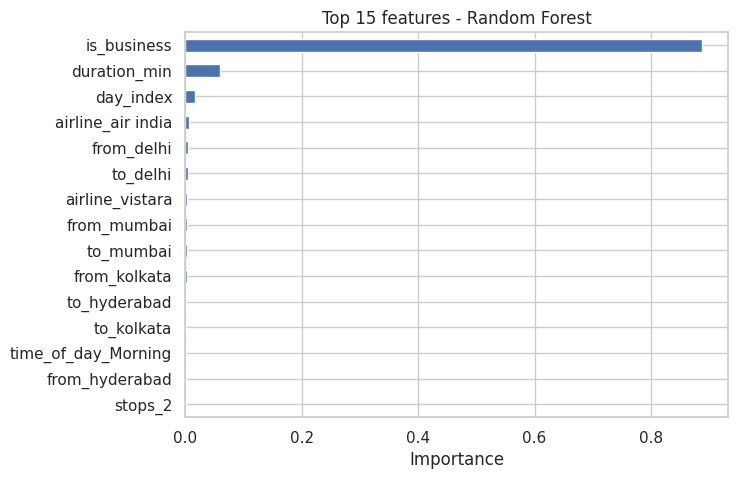

In [ ]:
imp = pd.Series(rf.feature_importances_, index=X_train.columns)
imp = imp.sort_values(ascending=False)
print(imp.round(4))

imp.head(15).sort_values().plot(kind='barh', figsize=(7, 5))
plt.title('Top 15 features - Random Forest')
plt.xlabel('Importance')
plt.show()

In [ ]:
err = pd.DataFrame({
    'actual': y_test.values,
    'predicted': rf_pred,
    'is_business': X_test['is_business'].values
})
err['error'] = err['actual'] - err['predicted']
err['abs_error'] = err['error'].abs()
err.head()

,actual,predicted,is_business,error,abs_error
0,6014.0,6568.587560,0,-554.587560,554.587560
1,6015.0,6303.118161,0,-288.118161,288.118161
2,6014.0,10016.785233,0,-4002.785233,4002.785233
3,6227.0,6741.509075,0,-514.509075,514.509075
4,10575.0,8219.966068,0,2355.033932,2355.033932


In [ ]:
for flag, name in [(0, 'Economy'), (1, 'Business')]:
    part = err[err['is_business'] == flag]
    mae = part['abs_error'].mean()
    median_price = part['actual'].median()

    print(name)
    print("  rows        :", len(part))
    print("  median price:", round(median_price))
    print("  MAE         :", round(mae))
    print("  MAE % of median price:", round(mae / median_price * 100, 1), "%")
    print("  R2          :", round(r2_score(part['actual'], part['predicted']), 3))

Economy
  rows        : 36130
  median price: 5854
  MAE         : 776
  MAE % of median price: 13.2 %
  R2          : 0.829
Business
  rows        : 16403
  median price: 53961
  MAE         : 2530
  MAE % of median price: 4.7 %
  R2          : 0.871


In [ ]:
for flag, name in [(0, 'Economy'), (1, 'Business')]:
    part = err[err['is_business'] == flag]
    pct_error = part['abs_error'] / part['actual'] * 100

    print(name)
    print("  within 10% of real price:", round((pct_error <= 10).mean() * 100, 1), "%")
    print("  within 20% of real price:", round((pct_error <= 20).mean() * 100, 1), "%")
    print("  worse than 50% off      :", round((pct_error > 50).mean() * 100, 1), "%")

Economy
  within 10% of real price: 66.0 %
  within 20% of real price: 83.1 %
  worse than 50% off      : 3.0 %
Business
  within 10% of real price: 85.2 %
  within 20% of real price: 95.6 %
  worse than 50% off      : 0.2 %


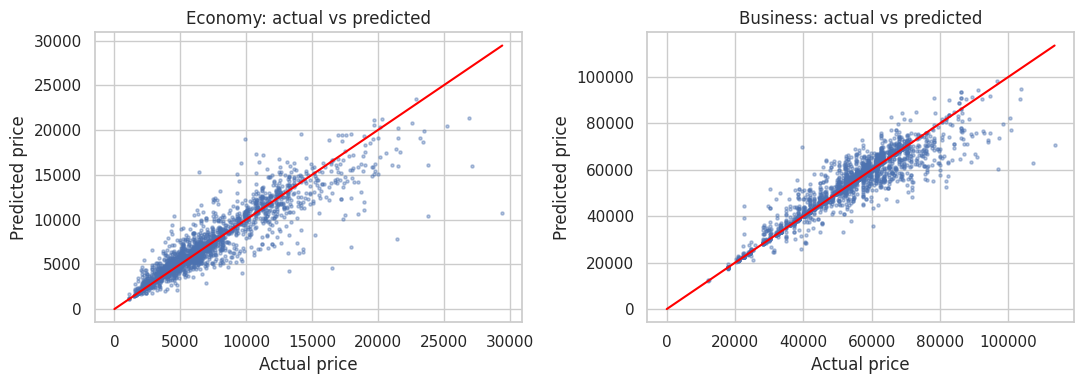

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, flag, name in [(axes[0], 0, 'Economy'), (axes[1], 1, 'Business')]:
    part = err[err['is_business'] == flag].sample(3000, random_state=1)
    ax.scatter(part['actual'], part['predicted'], s=5, alpha=0.4)
    top = max(part['actual'].max(), part['predicted'].max())
    ax.plot([0, top], [0, top], color='red')   # perfect prediction line
    ax.set_title(name + ': actual vs predicted')
    ax.set_xlabel('Actual price')
    ax.set_ylabel('Predicted price')

plt.tight_layout()
plt.show()

In [ ]:
err['day_index'] = X_test['day_index'].values
err['date_range'] = pd.cut(err['day_index'], bins=[-1, 6, 13, 27, 48],
                           labels=['Week 1', 'Week 2', 'Weeks 3-4', 'Weeks 5-7'])

summary = err.groupby(['is_business', 'date_range'], observed=True).agg(
    rows=('actual', 'size'),
    median_price=('actual', 'median'),
    MAE=('abs_error', 'mean')
).round()
summary['MAE_pct'] = (summary['MAE'] / summary['median_price'] * 100).round(1)
print(summary)

                         rows  median_price     MAE  MAE_pct
is_business date_range                                      
0           Week 1       3776       11276.0  1856.0     16.5
            Week 2       5174        9978.0  1213.0     12.2
            Weeks 3-4   10885        5283.0   699.0     13.2
            Weeks 5-7   16295        4803.0   438.0      9.1
1           Week 1       1901       56335.0  5066.0      9.0
            Week 2       2398       54746.0  2996.0      5.5
            Weeks 3-4    4948       53766.0  2199.0      4.1
            Weeks 5-7    7156       53310.0  1930.0      3.6


In [ ]:
import joblib
import json

joblib.dump(rf, 'flight_fare_rf.pkl', compress=3)

with open('feature_columns.json', 'w') as f:
    json.dump(list(X_train.columns), f)

In [ ]:
loaded_model = joblib.load('flight_fare_rf.pkl')

with open('feature_columns.json') as f:
    loaded_cols = json.load(f)

same = np.allclose(loaded_model.predict(X_test[loaded_cols]), rf_pred)
print("same predictions after reload:", same)

same predictions after reload: True


In [ ]:
from google.colab import files
files.download('flight_fare_rf.pkl')
files.download('feature_columns.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>